# Ajustar la correlación de activos a tasas de castigo: máxima verosimilitud, intervalos de perfil y backtest de cola

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (la distribución de pérdidas de Vasicek de una cartera grande)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- escribir la verosimilitud de una serie de tasas de pérdida anuales bajo el modelo de un factor, y ajustar la PD y la correlación de activos por máxima verosimilitud con el motor;
- ajustar los mismos dos números por el método de momentos, y decir por qué las dos estimaciones de la correlación difieren;
- medir la incertidumbre de la correlación con un intervalo de verosimilitud de perfil y con un bootstrap paramétrico, y leer una curva de perfil;
- convertir cada año observado en un factor sistemático implícito, el índice del ciclo de crédito del ajuste;
- hacer un backtest de la distribución ajustada en los seis años posteriores a la ventana de ajuste, y decir qué concluye un validador para cada uno de los cinco tipos de préstamo de los bancos de Estados Unidos;
- comparar la correlación ajustada con la correlación regulatoria IRB de la clase de activos más cercana.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los cinco archivos por tipo de préstamo del caso C10, uno por columna de la tabla de castigos de la Reserva Federal `chgallsa` (https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm; dominio público, clase de licencia `mirror-allowed`): préstamos comerciales e industriales, inmobiliario comercial, inmobiliario residencial, tarjetas de crédito y otro consumo de todos los bancos comerciales de Estados Unidos, 1985 a 2012. La ventana de ajuste es 1985 a 2006 y la de evaluación 2007 a 2012. En cada archivo:

- `outputs.annual_rates` tiene una fila por año con la tasa de pérdida, o `null` y el motivo cuando la tabla de la Junta no tiene valor para ese tipo de préstamo; un año faltante se excluye y se cuenta, nunca se interpola;
- `outputs.fit` guarda los ajustes versionados, `outputs.profile_likelihood` la curva de perfil versionada, `outputs.backtest` el backtest versionado y `outputs.irb_reference` la comparación regulatoria.

La celda siguiente carga los cinco archivos e imprime, para cada tipo de préstamo, cuántos años de la ventana de ajuste tienen tasa y qué ajustó el pipeline, con la versión del motor que lo calculó.

In [2]:
# Cargar los cinco artefactos por tipo de préstamo e imprimir los años utilizables y el ajuste versionado de cada uno
NAMES = {
    "commercial-industrial": "Comerciales e industriales",
    "commercial-real-estate": "Inmobiliario comercial",
    "residential": "Inmobiliario residencial",
    "credit-cards": "Tarjetas de crédito",
    "other-consumer": "Otro consumo",
}
docs = {k: json.loads((ROOT / "data" / "derived" / "C10" / f"{k}.json").read_text(encoding="utf-8")) for k in NAMES}

print("calculado con riskvalidation", {d["provenance"]["riskvalidation_version"] for d in docs.values()})
print(f"{'tipo de préstamo':30s} {'años de ajuste':>15s} {'PD (ML)':>10s} {'rho (ML)':>9s} {'rho (momentos)':>14s}")
for key, label in NAMES.items():
    out = docs[key]["outputs"]
    fit = out["fit"]
    print(f"{label:30s} {fit['n_years_used']:15d} {fit['maximum_likelihood']['pd']['estimate']:10.4f} "
          f"{fit['maximum_likelihood']['rho']['estimate']:9.4f} {fit['moments']['rho']['estimate']:14.4f}")

# Un tipo de préstamo con años faltantes: el motivo que registró el pipeline para el primero
missing = [r for r in docs["residential"]["outputs"]["annual_rates"] if r["loss_rate"] is None]
print("residencial, años sin tasa:", [r["year"] for r in missing])
print("el pipeline no registra tasa para estos años, porque la tabla de la Junta no tiene valor para este tipo de préstamo; se excluyen y se cuentan, nunca se interpolan")

calculado con riskvalidation {'0.7.0'}
tipo de préstamo                años de ajuste    PD (ML)  rho (ML) rho (momentos)
Comerciales e industriales                  22     0.0091    0.0637         0.0426
Inmobiliario comercial                      16     0.0044    0.2384         0.1560
Inmobiliario residencial                    16     0.0014    0.0129         0.0125
Tarjetas de crédito                         22     0.0423    0.0127         0.0124
Otro consumo                                22     0.0098    0.0109         0.0100
residencial, años sin tasa: [1985, 1986, 1987, 1988, 1989, 1990]
el pipeline no registra tasa para estos años, porque la tabla de la Junta no tiene valor para este tipo de préstamo; se excluyen y se cuentan, nunca se interpolan


## Método

### Paso 1: la verosimilitud y el ajuste por máxima verosimilitud

Bajo el modelo de un factor la tasa de pérdida anual $x_t$ de una cartera muy grande es $p(Z_t)$ con $Z_t$ normal estándar, así que $x_t$ tiene la densidad de la cartera grande (la derivada de la función de distribución del cuaderno 01; Vasicek, 2002, y Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8):

$$f(x;\mathrm{PD},\rho) = \sqrt{\frac{1-\rho}{\rho}}\; \exp\!\left(\tfrac12\,\Phi^{-1}(x)^2 - \frac{\left(\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(\mathrm{PD})\right)^2}{2\rho}\right)$$

Tomando los años como independientes, la log-verosimilitud de una serie es $\ell(\mathrm{PD},\rho)=\sum_t \ln f(x_t;\mathrm{PD},\rho)$, y la estimación es el par que la maximiza. `log_likelihood` del motor la evalúa y `fit_ml` la maximiza (una búsqueda Nelder-Mead en escala logit desde un inicio fijo, así que el resultado es determinista). La celda siguiente toma las 22 tasas de la ventana de ajuste de los préstamos comerciales e industriales, las ajusta y compara el resultado con el ajuste versionado.

In [3]:
# Ajustar por máxima verosimilitud las tasas de pérdida comerciales e industriales y compararlas con el ajuste versionado
from riskvalidation.portfolio.asrf_fit import fit_ml, log_likelihood

ci = docs["commercial-industrial"]["outputs"]
rows = ci["annual_rates"]
as_float = lambda r: np.nan if r["loss_rate"] is None else r["loss_rate"]
fit_rates = np.array([as_float(r) for r in rows if r["window"] == "fit"])
eval_rates = np.array([as_float(r) for r in rows if r["window"] == "evaluation"])
eval_years = [r["year"] for r in rows if r["window"] == "evaluation"]

est = fit_ml(fit_rates)
committed = ci["fit"]["maximum_likelihood"]
print("años usados:", est.n_years, "| faltantes:", est.n_missing, "| convergió:", si_no(est.converged))
print("PD:", round(est.pd, 8), "| versionada:", committed["pd"]["estimate"])
print("rho:", round(est.rho, 8), "| versionada:", committed["rho"]["estimate"])
print("log-verosimilitud:", round(est.log_likelihood, 6), "| versionada:", round(committed["log_likelihood"], 6))

# La verosimilitud evaluada en una grilla de correlaciones con la PD ajustada: el máximo debe estar en la estimación
rho_scan = np.linspace(0.01, 0.30, 59)
ll_scan = np.array([log_likelihood(fit_rates, est.pd, r) for r in rho_scan])
print("mejor rho de la grilla:", round(float(rho_scan[ll_scan.argmax()]), 3), "| estimación:", round(est.rho, 3))

años usados: 22 | faltantes: 0 | convergió: sí
PD: 0.0091049 | versionada: 0.00910490011
rho: 0.06367655 | versionada: 0.0636765484
log-verosimilitud: 84.82321 | versionada: 84.82321
mejor rho de la grilla: 0.065 | estimación: 0.064


La log-verosimilitud es una curva en $\rho$ con un solo pico, y el pico es la estimación. Su ancho es la información que los 22 años tienen sobre la correlación: una cima plana significa que los datos apenas distinguen valores vecinos. La celda siguiente la dibuja.

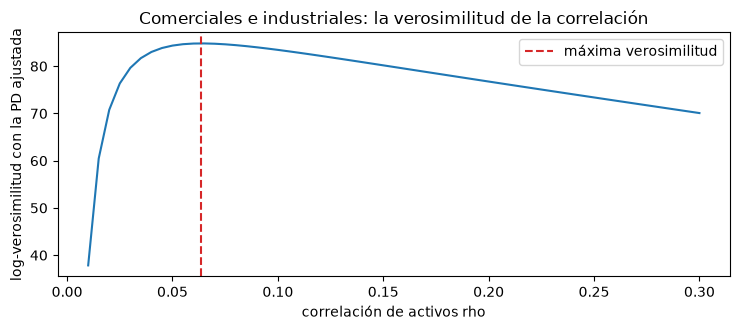

In [4]:
# Dibujar la log-verosimilitud en la correlación con la PD ajustada
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(rho_scan, ll_scan, color="tab:blue")
ax.axvline(est.rho, color="tab:red", linestyle="--", label="máxima verosimilitud")
ax.set_xlabel("correlación de activos rho")
ax.set_ylabel("log-verosimilitud con la PD ajustada")
ax.set_title("Comerciales e industriales: la verosimilitud de la correlación")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 2: el método de momentos, una alternativa que discrepa

Un estimador más simple iguala dos momentos. La media de la tasa de pérdida es la PD, y el segundo momento de la fracción de incumplimientos de la cartera grande es la probabilidad de que dos deudores caigan juntos en incumplimiento, $E[p(Z)^2]$ (el resultado del dossier, dossier 04 C.4). La estimación es la PD igual a la media de las tasas y la correlación que hace que $E[p(Z)^2]$ sea igual a la media de las tasas al cuadrado. `fit_moments` del motor lo resuelve por búsqueda de raíz, y lanza un error en lugar de devolver cero cuando las tasas no muestran dispersión en exceso. La celda siguiente ajusta ambos estimadores y evalúa la verosimilitud en cada uno, para compararlos en la misma escala.

In [5]:
# Ajustar por momentos, comparar con el ajuste versionado y evaluar la verosimilitud en ambas estimaciones
from riskvalidation.portfolio.asrf_fit import fit_moments

mom = fit_moments(fit_rates)
committed_mom = ci["fit"]["moments"]
print("momentos: PD", round(mom.pd, 8), "| rho", round(mom.rho, 8))
print("versionado:  PD", committed_mom["pd"]["estimate"], "| rho", committed_mom["rho"]["estimate"])
print("media de las tasas:", round(float(fit_rates.mean()), 8), "| media de las tasas al cuadrado:", f"{float((fit_rates ** 2).mean()):.4e}")
print(f"{'':22s} rho      log-verosimilitud")
print(f"{'máxima verosimilitud':22s} {est.rho:.4f}   {est.log_likelihood:.4f}")
print(f"{'momentos':22s} {mom.rho:.4f}   {log_likelihood(fit_rates, mom.pd, mom.rho):.4f}")

momentos: PD 0.00897159 | rho 0.04259409
versionado:  PD 0.00897159091 | rho 0.0425940918
media de las tasas: 0.00897159 | media de las tasas al cuadrado: 1.0866e-04
                       rho      log-verosimilitud
máxima verosimilitud   0.0637   84.8232
momentos               0.0426   83.5628


### Paso 3: la verosimilitud de perfil y su intervalo

Una estimación puntual de $\rho$ no dice nada de cuán bien la fijan 22 años. La **log-verosimilitud de perfil** fija $\rho$ en cada valor de una grilla, maximiza sobre la PD y registra el máximo: $\ell_p(\rho)=\max_{\mathrm{PD}}\ell(\mathrm{PD},\rho)$. El intervalo de razón de verosimilitud conserva los valores de $\rho$ cuyo perfil está a menos de $\chi^2_{1;0{,}95}/2 = 1{,}9207$ de la cima. `profile_likelihood` del motor evalúa la curva en una grilla y `profile_interval` encuentra los extremos. La celda siguiente recalcula la curva versionada en su propia grilla de 42 puntos, halla el intervalo y compara ambos con el archivo.

In [6]:
# Recalcular la curva de perfil versionada y el intervalo de razón de verosimilitud, y compararlos con el archivo
from scipy import stats

from riskvalidation.portfolio.asrf_fit import profile_interval, profile_likelihood

profile = ci["profile_likelihood"]
grid = np.array(profile["rho"])
ll_profile, pd_at_rho = profile_likelihood(fit_rates, grid)
print("puntos de la grilla:", len(grid), "| mayor diferencia con la curva versionada:", f"{np.abs(ll_profile - np.array(profile['log_likelihood'])).max():.1e}")

drop = stats.chi2.ppf(0.95, 1) / 2
print("caída bajo la cima para 95%:", round(float(drop), 4), "| corte versionado:", round(profile["cutoff"], 4), "| cima:", round(profile["max_log_likelihood"], 4))

interval = profile_interval(fit_rates, 0.95)
print("rho intervalo al 95%:", tuple(round(v, 4) for v in interval["rho"]), "| versionado:", (round(committed["rho"]["ci_low"], 4), round(committed["rho"]["ci_high"], 4)))
print("PD intervalo al 95%:", tuple(round(v, 5) for v in interval["pd"]), "| versionado:", (round(committed["pd"]["ci_low"], 5), round(committed["pd"]["ci_high"], 5)))

puntos de la grilla: 42 | mayor diferencia con la curva versionada: 0.0e+00
caída bajo la cima para 95%: 1.9207 | corte versionado: 82.9025 | cima: 84.8232
rho intervalo al 95%: (0.0382, 0.1158) | versionado: (0.0382, 0.1158)
PD intervalo al 95%: (0.0068, 0.01297) | versionado: (0.0068, 0.01297)


La imagen muestra por qué el intervalo es asimétrico: el perfil cae despacio hacia la derecha, así que las correlaciones altas siguen siendo plausibles mucho después de que las bajas quedan excluidas. La celda siguiente dibuja el perfil, el corte, el intervalo y la estimación de momentos.

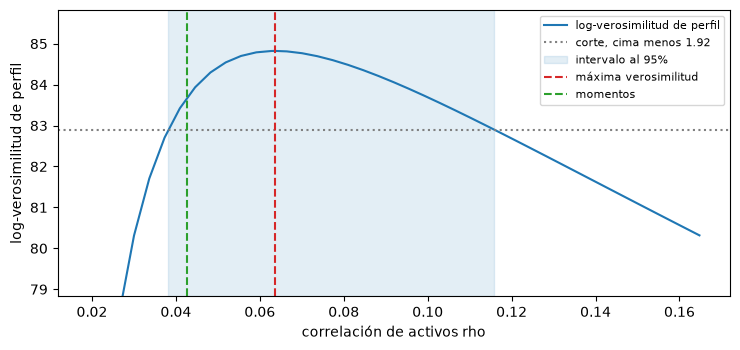

In [7]:
# Dibujar la log-verosimilitud de perfil con su corte, el intervalo y la estimación de momentos
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(grid, ll_profile, color="tab:blue", label="log-verosimilitud de perfil")
ax.axhline(est.log_likelihood - drop, color="gray", linestyle=":", label="corte, cima menos 1.92")
ax.axvspan(*interval["rho"], color="tab:blue", alpha=0.12, label="intervalo al 95%")
ax.axvline(est.rho, color="tab:red", linestyle="--", label="máxima verosimilitud")
ax.axvline(mom.rho, color="tab:green", linestyle="--", label="momentos")
ax.set_xlabel("correlación de activos rho")
ax.set_ylabel("log-verosimilitud de perfil")
ax.set_ylim(est.log_likelihood - 6, est.log_likelihood + 1)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Paso 4: un bootstrap paramétrico para la estimación de momentos

El método de momentos no tiene verosimilitud que perfilar, así que su incertidumbre viene de un **bootstrap paramétrico**: tomar el $(\mathrm{PD},\rho)$ ajustado, sortear 22 factores sistemáticos nuevos $z_t \sim N(0,1)$, convertir cada uno en una tasa de pérdida $p(z_t)$, reajustar y repetir. Los percentiles 2,5% y 97,5% de los valores reajustados son el intervalo. `bootstrap_interval` del motor lo hace con un generador con semilla, así que es reproducible; un reajuste que falla se descarta y se cuenta. La celda siguiente corre 500 reajustes con la semilla del pipeline y compara el intervalo con el versionado.

In [8]:
# Correr el bootstrap con semilla de la estimación de momentos y comparar su intervalo con el versionado
from riskvalidation.portfolio.asrf_fit import bootstrap_interval

boot = bootstrap_interval(fit_rates, "moments", 500, 4007, 0.95)
print("reajustes:", boot.n_boot, "| descartados:", boot.n_dropped)
print("rho intervalo bootstrap:", tuple(round(v, 4) for v in boot["rho"]), "| versionado:", (round(committed_mom["rho"]["ci_low"], 4), round(committed_mom["rho"]["ci_high"], 4)))
print("PD intervalo bootstrap:", tuple(round(v, 5) for v in boot["pd"]), "| versionado:", (round(committed_mom["pd"]["ci_low"], 5), round(committed_mom["pd"]["ci_high"], 5)))
print("estimación de momentos dentro del intervalo de verosimilitud:", si_no(interval["rho"][0] <= mom.rho <= interval["rho"][1]))

reajustes: 500 | descartados: 0
rho intervalo bootstrap: (0.0189, 0.0755) | versionado: (0.0189, 0.0755)
PD intervalo bootstrap: (0.00727, 0.01136) | versionado: (0.00727, 0.01136)
estimación de momentos dentro del intervalo de verosimilitud: sí


### Paso 5: el factor sistemático implícito de cada año

Dado el $(\mathrm{PD},\rho)$ ajustado, cada tasa de pérdida anual implica el valor del factor sistemático que la habría producido, la inversa de la PD condicional del cuaderno 01:

$$\hat z_t = \frac{\Phi^{-1}(\mathrm{PD}) - \sqrt{1-\rho}\,\Phi^{-1}(x_t)}{\sqrt{\rho}}$$

La serie $\hat z_t$ es el índice del ciclo de crédito del ajuste: negativa en los años malos, positiva en los buenos (Belkin, Suchower y Forest, 1998; aquí una derivación del modelo, no una ecuación citada). Si el modelo fuera correcto, los $\hat z_t$ se verían como sorteos de una normal estándar. `implied_factors` del motor calcula toda la serie y deja NaN donde falta un año. La celda siguiente la calcula para los 28 años, la compara con la columna versionada y la dibuja con las dos ventanas marcadas.

mayor diferencia con los factores versionados: 4.8e-09
media y desviación estándar de los factores de la ventana de ajuste: -0.0 1.024
factor más bajo: 2009 -1.708
autocorrelación de rezago 1 de los 28 factores: 0.761


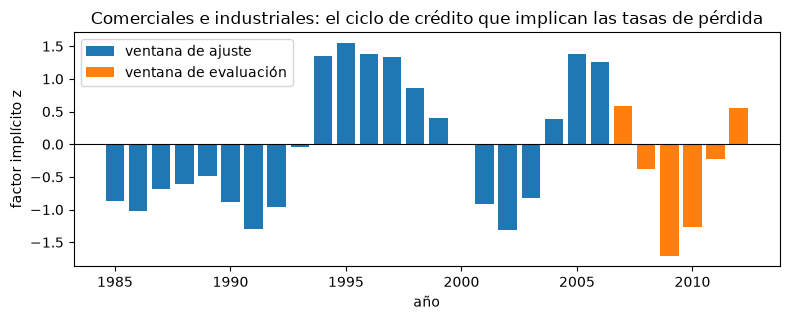

In [9]:
# Calcular los factores implícitos de los 28 años, compararlos con la columna versionada y dibujarlos
from riskvalidation.portfolio.asrf_fit import implied_factors

all_rates = np.array([as_float(r) for r in rows])
all_years = np.array([r["year"] for r in rows])
in_fit = np.array([r["window"] == "fit" for r in rows])
z_hat = implied_factors(all_rates, est.pd, est.rho)
z_file = np.array([r["implied_factor"] for r in rows], dtype=float)
print("mayor diferencia con los factores versionados:", f"{np.nanmax(np.abs(z_hat - z_file)):.1e}")
print("media y desviación estándar de los factores de la ventana de ajuste:", round(float(z_hat[in_fit].mean()), 3), round(float(z_hat[in_fit].std(ddof=1)), 3))
print("factor más bajo:", int(all_years[np.nanargmin(z_hat)]), round(float(np.nanmin(z_hat)), 3))
print("autocorrelación de rezago 1 de los 28 factores:", round(float(np.corrcoef(z_hat[:-1], z_hat[1:])[0, 1]), 3))

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(all_years[in_fit], z_hat[in_fit], color="tab:blue", label="ventana de ajuste")
ax.bar(all_years[~in_fit], z_hat[~in_fit], color="tab:orange", label="ventana de evaluación")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("año")
ax.set_ylabel("factor implícito z")
ax.set_title("Comerciales e industriales: el ciclo de crédito que implican las tasas de pérdida")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 6: un backtest de cola en los seis años posteriores al ajuste

Una distribución ajustada hace una predicción: en $n$ años futuros, el número de años sobre su cuantil $q$ es Binomial$(n, 1-q)$. `tail_backtest` del motor cuenta los años de la ventana de evaluación sobre los cuantiles ajustados al 95%, 99% y 99,9% e informa la cola binomial superior $P(X \ge \text{observado})$ como su valor p, al nivel primario de 99%; es una puerta interna de Contraste con la luz verde desde un valor p de 0,05 y roja bajo 0,01, no un umbral regulatorio. Con seis años la prueba tiene poca potencia, así que los conteos se muestran junto al valor p. La celda siguiente la corre con los préstamos comerciales e industriales y compara con la fila versionada.

In [10]:
# Hacer el backtest del ajuste comercial e industrial en 2007 a 2012 y compararlo con la fila versionada
from riskvalidation.validation.portfolio import tail_backtest

result = tail_backtest(eval_rates, est.pd, est.rho, levels=(0.95, 0.99, 0.999), primary_level=0.99, model_id="m-lhp")
print("luz:", si_no(result.light.value), "| p-value:", round(result.p_value, 6), "| observado al 99%:", int(result.statistic), "| esperado:", round(result.metric, 4))
print(f"{'q':>6s} {'cuantil ajustado':>16s} {'esperados':>10s} {'observados':>10s} {'p':>8s}  años")
for row in result.extras["levels"]:
    print(f"{row['level']:6.3f} {row['fitted_quantile']:16.5f} {row['expected']:10.3f} {row['observed']:10d} {row['p_value']:8.4f}  {[eval_years[i] for i in row['years_exceeding']]}")

file_row = next(t for t in docs["commercial-industrial"]["tests"] if t["test_id"] == "portfolio.tail_backtest")
print("valor p versionado:", file_row["p_value"], "| luz versionada:", si_no(file_row["light"]))

luz: verde | p-value: 1.0 | observado al 99%: 0 | esperado: 0.06
     q cuantil ajustado  esperados observados        p  años
 0.950          0.02214      0.300          1   0.2649  [2009]
 0.990          0.03335      0.060          0   1.0000  []
 0.999          0.05109      0.006          0   1.0000  []
valor p versionado: 1.0 | luz versionada: verde


La misma cadena de pasos corre para cada tipo de préstamo. La celda siguiente ajusta la ventana de ajuste de cada tipo, mide el intervalo de perfil, hace el backtest de la ventana de evaluación y recalcula la correlación regulatoria IRB de la clase de activos más cercana con `capital_requirement` del motor (Basel Framework CRE31, https://www.bis.org/basel_framework/chapter/CRE/31.htm; la clase es la clase regulatoria más cercana, no una afirmación de que la serie de la Junta sea esa clase). Imprime una fila por tipo de préstamo: la correlación ajustada y su intervalo, la correlación IRB, los años sobre el cuantil 99% ajustado y la luz.

In [11]:
# Ajustar, perfilar, hacer backtest y comparar con la correlación IRB para los cinco tipos de préstamo
from riskvalidation.regulatory.irb import capital_requirement

print(f"{'tipo de préstamo':26s} {'años':>5s} {'rho':>7s} {'intervalo 95%':>17s} {'rho IRB':>8s} {'>q99':>5s} {'p':>9s} luz")
for key, label in NAMES.items():
    out_k = docs[key]["outputs"]
    rows_k = out_k["annual_rates"]
    fit_k = np.array([as_float(r) for r in rows_k if r["window"] == "fit"])
    eval_k = np.array([as_float(r) for r in rows_k if r["window"] == "evaluation"])
    fitted = fit_ml(fit_k)
    band = profile_interval(fit_k, 0.95)["rho"]
    test = tail_backtest(eval_k, fitted.pd, fitted.rho, levels=(0.95, 0.99, 0.999), primary_level=0.99, model_id="m-lhp")
    ref = out_k["irb_reference"]
    extra = {} if ref["asset_class"] in ("residential_mortgage", "qrre", "other_retail") else {"maturity": 2.5}
    irb_k = capital_requirement(ref["asset_class"], fitted.pd, 0.45, regime="basel3", **extra)
    print(f"{label:26s} {fitted.n_years:5d} {fitted.rho:7.4f} {band[0]:8.4f}-{band[1]:.4f} {irb_k.correlation:8.4f} {int(test.statistic):5d} {test.p_value:9.2e} {si_no(test.light.value)}")
    assert abs(fitted.rho - out_k["fit"]["maximum_likelihood"]["rho"]["estimate"]) < 1e-6  # el ajuste versionado se reproduce

tipo de préstamo            años     rho     intervalo 95%  rho IRB  >q99         p luz
Comerciales e industriales    22  0.0637   0.0382-0.1158   0.1961     0  1.00e+00 verde
Inmobiliario comercial        16  0.2384   0.1440-0.4066   0.2647     0  1.00e+00 verde
Inmobiliario residencial      16  0.0129   0.0070-0.0278   0.1500     5  5.95e-10 rojo
Tarjetas de crédito           22  0.0127   0.0075-0.0242   0.0400     2  1.46e-03 rojo
Otro consumo                  22  0.0109   0.0064-0.0208   0.1224     3  1.96e-05 rojo


La fórmula regulatoria y el ajuste responden preguntas distintas, así que comparamos su capital y no solo sus correlaciones. El bloque versionado `irb_reference` guarda, por tipo de préstamo, el capital de la cartera grande al 99,9% con la correlación ajustada y el capital IRB $K$, ambos con la misma PD, una LGD de 45% y el mismo ajuste por vencimiento; su razón es el número versionado que cita la vista ejecutiva. La celda siguiente recalcula el capital ajustado con la correlación ajustada y el ajuste por vencimiento IRB, y pone la razón junto a la versionada.

In [12]:
# Recalcular el capital ajustado al 99.9% y su razón con el capital IRB, y compararlos con el bloque versionado
from riskvalidation.engines.vasicek import lhp_quantile

print(f"{'tipo de préstamo':26s} {'capital ajustado':>16s} {'K IRB':>8s} {'razón':>8s} {'razón versionada':>18s}")
for key, label in NAMES.items():
    out_k = docs[key]["outputs"]
    ref = out_k["irb_reference"]
    fit_k = np.array([as_float(r) for r in out_k["annual_rates"] if r["window"] == "fit"])
    fitted = fit_ml(fit_k)
    extra = {} if ref["asset_class"] in ("residential_mortgage", "qrre", "other_retail") else {"maturity": 2.5}
    irb_k = capital_requirement(ref["asset_class"], fitted.pd, 0.45, regime="basel3", **extra)
    adjustment = irb_k.maturity_adjustment or 1.0
    capital = 0.45 * (float(lhp_quantile(0.999, fitted.pd, fitted.rho)) - fitted.pd) * adjustment
    print(f"{label:26s} {capital:16.5f} {float(irb_k.k):8.5f} {capital / float(irb_k.k):8.3f} {ref['ratio_fitted_to_irb']:18.3f}")

tipo de préstamo           capital ajustado    K IRB    razón   razón versionada
Comerciales e industriales          0.02397  0.07137    0.336              0.336
Inmobiliario comercial              0.05870  0.06679    0.879              0.879
Inmobiliario residencial            0.00115  0.01102    0.104              0.104
Tarjetas de crédito                 0.01835  0.03917    0.468              0.468
Otro consumo                        0.00529  0.03622    0.146              0.146


## Resultados

- **El ajuste reproduce el versionado.** Con los 22 años de la ventana de ajuste de los préstamos comerciales e industriales, la máxima verosimilitud da una PD de 0,91% y una correlación de 0,0637, iguales a los valores versionados hasta los dígitos impresos, con una log-verosimilitud de 84,82. El pipeline calculó los archivos con el motor 0.7.0 y el motor instalado es el 0.8.1, así que cada igualdad de este cuaderno (la curva de perfil, los intervalos, los factores y la fila del backtest) es una comprobación de reproducibilidad entre dos versiones del motor.
- **Los dos estimadores discrepan, y la verosimilitud dice cuál ajusta mejor.** El método de momentos da una correlación de 0,0426, frente a 0,0637 de la máxima verosimilitud; la log-verosimilitud es 83,56 en la estimación de momentos y 84,82 en el máximo. La estimación de momentos queda dentro del intervalo de verosimilitud, así que los datos no la excluyen, pero es la menos eficiente de las dos.
- **Veintidós años fijan la correlación solo de forma laxa.** El intervalo de razón de verosimilitud va de 0,0382 a 0,1158, un rango de un factor de tres, y es asimétrico: el perfil cae despacio hacia la derecha. El intervalo bootstrap de la estimación de momentos, de 0,0189 a 0,0755, viene de 500 reajustes con semilla y ninguno se descartó. Toda cifra de capital que dependa de la correlación hereda este rango.
- **El ciclo de crédito es persistente, y el modelo supone que no lo es.** Los factores implícitos de la ventana de ajuste tienen media 0,0 y desviación estándar 1,02, como tendría una normal estándar, y el más bajo es 2009 con -1,71. Pero la autocorrelación de rezago 1 de los 28 factores es 0,76: a un mal año tiende a seguirle otro. La verosimilitud trata los años como independientes, así que su intervalo es condicional a ese supuesto y probablemente optimista.
- **El backtest separa los tipos de préstamo.** Para los préstamos comerciales e industriales ningún año de evaluación supera el cuantil 99% ajustado (se esperan 0,06) y uno supera el cuantil 95% (2009, se esperan 0,30): verde, p = 1,0. El inmobiliario comercial también es verde. El inmobiliario residencial tiene 5 de 6 años sobre el cuantil 99% (p = 6e-10), las tarjetas de crédito 2 de 6 (p = 0,0015) y otro consumo 3 de 6 (p = 2e-5): todos en rojo. Los tres tipos minoristas se ajustaron con una ventana sin la crisis de 2007 a 2009 (el residencial además tiene solo 16 años utilizables, pues la tabla de la Junta no tiene valor antes de 1991), y la ventana de evaluación es esa crisis. La prueba no dice que el modelo de un factor sea incorrecto; dice que un ajuste sobre una ventana benigna subestima la cola que luego encuentra.
- **La correlación ajustada queda bajo la regulatoria en los cinco tipos, y muy por debajo en cuatro.** Comerciales e industriales: 0,0637 frente a 0,1961 de IRB; residencial: 0,0129 frente a 0,15; tarjetas: 0,0127 frente a 0,04; otro consumo: 0,0109 frente a 0,1224. El inmobiliario comercial es el cercano, 0,2384 frente a 0,2647. Las razones de capital ajustado sobre IRB son 0,336, 0,104, 0,468, 0,146 y 0,879, los valores versionados. La comparación mide el tamaño de la brecha y no su causa: las correlaciones IRB son calibraciones supervisoras, y nada aquí dice que estén equivocadas.

Lo que este cuaderno no muestra: cuán bien recupera cada estimador una correlación conocida (el estudio de tamaño y potencia, cuadernos 06 y 08), qué implica la correlación para una cartera finita (cuadernos 03 a 05), o cómo cambia el intervalo cuando los años son dependientes.

## Resumen

- La verosimilitud de las tasas de pérdida anuales bajo el modelo de un factor es la suma de las log-densidades de la cartera grande; `fit_ml` la maximiza y `fit_moments` iguala los dos primeros momentos, y los dos difieren.
- La incertidumbre de la correlación es un intervalo de verosimilitud de perfil (`profile_likelihood`, `profile_interval`) o un bootstrap paramétrico con semilla (`bootstrap_interval`); con 22 años abarca un factor de tres.
- `implied_factors` convierte cada año en el índice del ciclo de crédito del ajuste; su fuerte autocorrelación dice que el supuesto de años independientes es optimista.
- `tail_backtest` cuenta años de evaluación sobre los cuantiles ajustados frente a una binomial; aprueba los préstamos comerciales y reprueba los tipos minoristas ajustados sobre una ventana benigna.
- La correlación ajustada queda bajo la IRB en los cinco tipos, y la razón de capital frente a IRB es el número que hay que leer, con el intervalo al lado.

**Qué probar a continuación.** Cambia la ventana de ajuste a 1985 a 2009 para los tipos minoristas y repite el backtest en 2010 a 2012. Luego abre el cuaderno 03, donde la correlación ajustada gobierna un Monte Carlo de una cartera finita.

## Referencias

- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- BCBS, Basel Framework, CRE31: IRB approach, risk weight functions for corporate, bank, sovereign and retail exposures. https://www.bis.org/basel_framework/chapter/CRE/31.htm
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Belkin, B., Suchower, S. y Forest, L. (1998), A one-parameter representation of credit risk and transition matrices, CreditMetrics Monitor, as cited by the engine's `engines.vasicek` module.
- Persisted research dossier 04 of this product (credit-risk models, state of the art), sections C.4 (the Vasicek model and the moment equation) and H.1 (the loss measures).
- The engine's contract for these functions: `docs/contracts/engine/` of this repository.